In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
df_temp = pd.read_csv('../Part1_analysis/target_temp_SEE_quadr_moanom.csv')
df_feature = pd.read_csv('../Part1_analysis/sm_lower_SEE_week3_detr.csv')
df_temp_terc = pd.read_csv('../Part1_analysis/southeastern_temperature_terc_cat_new.csv')

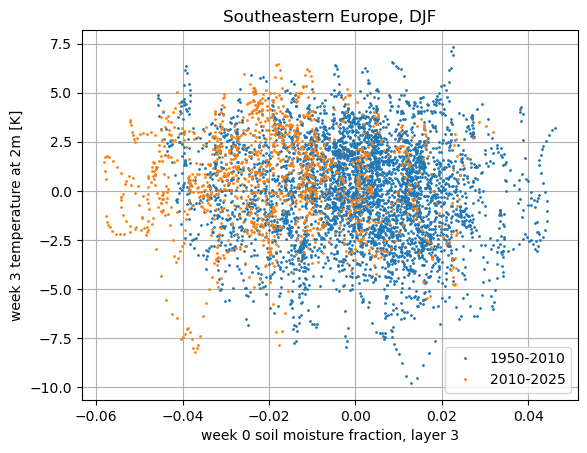

In [3]:
plt.plot(df_feature['soil_moist_lower'][:5040], df_temp['t2m'][:5040], 'o', markersize=1, label='1950-2010')
plt.plot(df_feature['soil_moist_lower'][5040:], df_temp['t2m'][5040:], 'o', markersize=1, label='2010-2025')
plt.xlabel('week 0 soil moisture fraction, layer 3')
plt.ylabel('week 3 temperature at 2m [K]')
plt.title('Southeastern Europe, DJF')
plt.legend()
plt.grid()
plt.savefig('SEE_temp_sm_scatter.png', bbox_inches='tight')

In [3]:
low_temp_train = df_feature[840:5040][df_temp_terc[840:5040]['tercile_category']==0]['soil_moist_lower']
medium_temp_train = df_feature[840:5040][df_temp_terc[840:5040]['tercile_category']==1]['soil_moist_lower']
high_temp_train = df_feature[840:5040][df_temp_terc[840:5040]['tercile_category']==2]['soil_moist_lower']

low_temp_test = df_feature[5040:][df_temp_terc[5040:]['tercile_category']==0]['soil_moist_lower']
medium_temp_test = df_feature[5040:][df_temp_terc[5040:]['tercile_category']==1]['soil_moist_lower']
high_temp_test = df_feature[5040:][df_temp_terc[5040:]['tercile_category']==2]['soil_moist_lower']

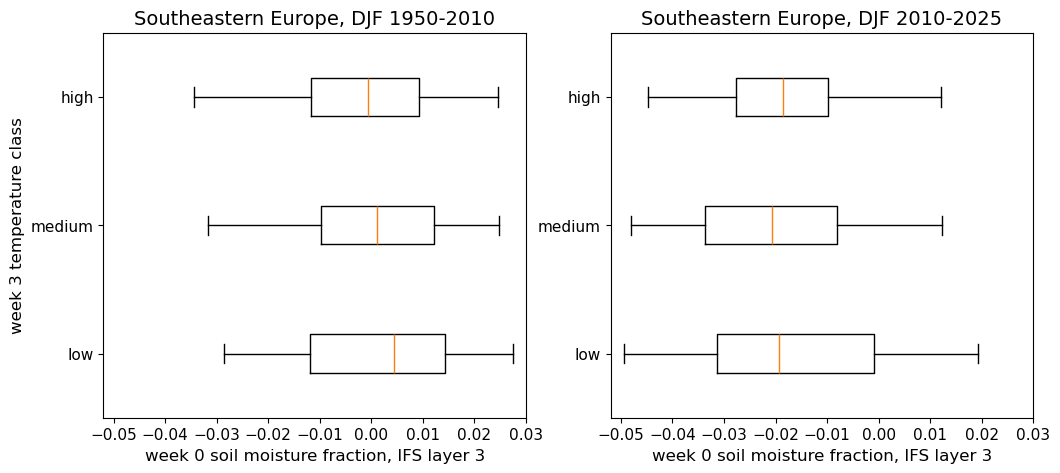

In [4]:
fig, ax = plt.subplots(1,2,figsize=(12,5))

ax[0].boxplot([low_temp_train, medium_temp_train, high_temp_train], orientation='horizontal', whis=[5,95], sym="", tick_labels=['low', 'medium', 'high'])
ax[0].set_xlabel('week 0 soil moisture fraction, IFS layer 3',fontsize=12)
ax[0].set_ylabel('week 3 temperature class',fontsize=12)
ax[0].set_title('Southeastern Europe, DJF 1950-2010',fontsize=14)
ax[0].set_xlim((-0.052,0.03))
ax[0].tick_params(labelsize=11)

ax[1].boxplot([low_temp_test, medium_temp_test, high_temp_test], orientation='horizontal', whis=[5,95], sym="", tick_labels=['low', 'medium', 'high'])
ax[1].set_xlabel('week 0 soil moisture fraction, IFS layer 3',fontsize=12)
ax[1].set_title('Southeastern Europe, DJF 2010-2025',fontsize=14)
ax[1].set_xlim((-0.052,0.03))
ax[1].tick_params(labelsize=11)

plt.savefig('SEE_temp_sm_box.pdf', bbox_inches='tight')